[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FBE5d5wqfds/EAIF-/blob/main/practicals_L1/L1_P1_cost_regression_solution.ipynb)


# Lecture 1 · Practical 1 — How much will each customer cost next year?
### Regression with neural networks: losses, embeddings, recurrent networks — and an honest verdict

**Version: instructor solution**

### Where this notebook sits in Lecture 1
Lecture 1 follows one business decision from start to finish.

> **The decision.** *Arvena*, a (fictional) Swiss health insurer, must file its basic-insurance premiums for 2027. By law, the premium must cover the expected cost of care of its insured, and Arvena may not make a profit on basic insurance. A premium that is too low produces losses; one that is too high drives customers to competitors.

| notebook | question | machine-learning task | what it shows about neural networks |
|---|---|---|---|
| **P1 (this one)** | How much will each customer cost in 2027, and how much money will Arvena need in total? | regression | they **do not** beat simpler models here — and we find out why |
| P2 | Which customers leave at a given price, and which premium covers the cost of those who stay? | classification + decision | accuracy equal, but a constrained network gives safer price answers |
| P3 | Which members of Arvena's step-bonus app will be admitted to hospital in the next 45 days? | classification on sequences | they **clearly** beat all other models — and we find out why |

P1 produces a file with the predicted 2027 cost of every Arvena customer. P2 uses it to choose the premium.

**Why predict each person when the premium is the same for everybody in a region?** Because the total cost of a region is the sum of the costs of the *people* in it, and those people change: they age, newcomers arrive, and some customers leave. P2 shows that the customers who leave are mostly cheap ones, so Arvena must know *who* is cheap and who is expensive.

### Learning goals
1. Read a skewed cost distribution on its natural scale and on a log scale, and explain why a model for the **mean** needs a Tweedie (or Poisson) loss rather than squared error on log costs.
2. Build a multilayer perceptron with **entity embeddings for every categorical variable**, and recurrent networks (**RNN, LSTM**) over monthly claim histories.
3. Compare networks fairly with a GLM and gradient boosting, and judge model quality in **absolute** terms against a ceiling.
4. Find **who** is mispredicted, in which direction, and whether it matters for the insurer.
5. Turn individual predictions into the **total money** Arvena needs.

Cells marked **✏️ YOUR CODE HERE** are exercises; the instructor version shows a solution (**✅ SOLUTION**). Keep `course_utils.py` and the `data/` folder next to this notebook. Runtime: about 4 minutes on a laptop CPU.

## 0 · Setup

In [1]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.linear_model import TweedieRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
import course_utils as cu

SEED = 2026
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
pd.set_option("display.precision", 3); pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
Path("outputs").mkdir(exist_ok=True)

## 1 · The target: what does a year of health care cost?

The table `person_years` has one row per insured person and calendar year. Our target is `okp_gross_cost`: the total of all invoices covered by basic insurance in a year — doctor visits, drugs, hospital stays — **before** the patient's own share is deducted.

### 1.1 · First look, on the natural scale (Swiss francs)

84,060 person-years · share with zero cost: 9.4%
mean CHF 4,192 · median CHF 1,175 · maximum CHF 243,683
quantiles (CHF): {'10.0%': '38', '25.0%': '291', '50.0%': '1,175', '75.0%': '3,790', '90.0%': '11,543', '99.0%': '40,334', '99.9%': '88,259'}


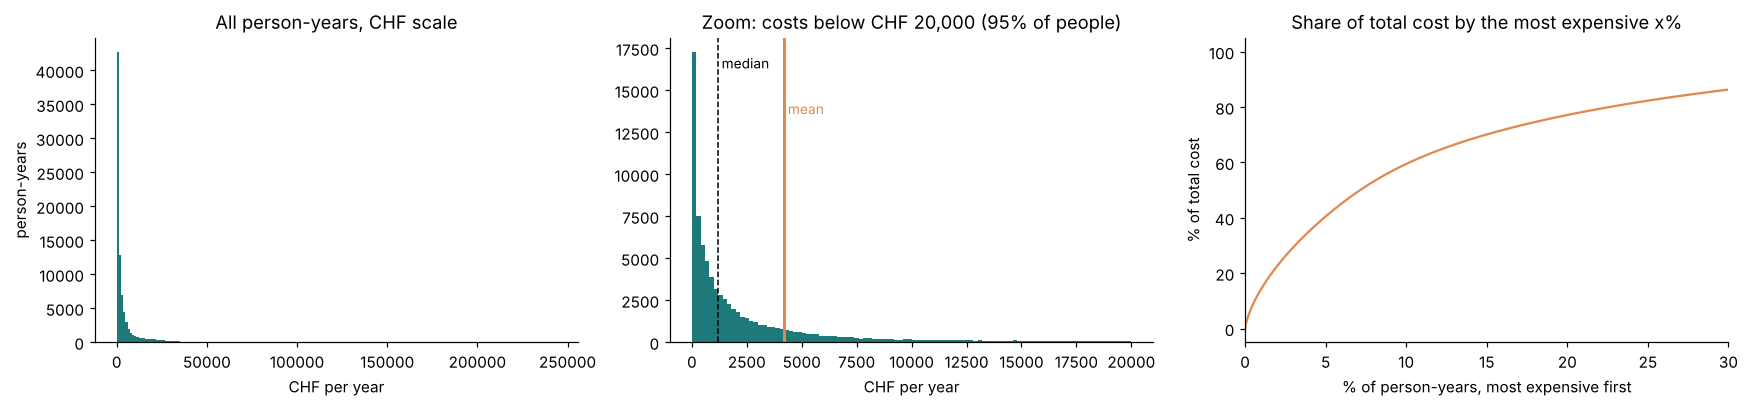

the most expensive 1% of person-years cause 14% of all cost; the top 10% cause 59%


In [2]:
py = cu.load("person_years")
c = py.okp_gross_cost
print(f"{len(c):,} person-years · share with zero cost: {(c == 0).mean():.1%}")
print(f"mean CHF {c.mean():,.0f} · median CHF {c.median():,.0f} · maximum CHF {c.max():,.0f}")
q = c.quantile([.10, .25, .50, .75, .90, .99, .999]).round(0)
print("quantiles (CHF):", {f"{int(k*1000)/10}%": f"{v:,.0f}" for k, v in q.items()})

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(c, bins=200, color="#1E7A7A"); ax[0].set(title="All person-years, CHF scale", xlabel="CHF per year", ylabel="person-years")
ax[1].hist(c[c < 20000], bins=100, color="#1E7A7A"); ax[1].set(title="Zoom: costs below CHF 20,000 (95% of people)", xlabel="CHF per year")
ax[1].axvline(c.median(), color="k", ls="--", lw=1); ax[1].axvline(c.mean(), color="#E08A4F", lw=2)
ax[1].text(c.median(), ax[1].get_ylim()[1] * .9, " median", fontsize=9); ax[1].text(c.mean(), ax[1].get_ylim()[1] * .75, " mean", color="#E08A4F", fontsize=9)
s = np.sort(c.values)[::-1]; share = np.cumsum(s) / s.sum()
ax[2].plot(np.arange(1, len(s) + 1) / len(s) * 100, share * 100, color="#E08A4F")
ax[2].set(title="Share of total cost by the most expensive x%", xlabel="% of person-years, most expensive first", ylabel="% of total cost", xlim=(0, 30))
plt.tight_layout(); plt.show()
print(f"the most expensive 1% of person-years cause {share[len(s)//100]:.0%} of all cost; the top 10% cause {share[len(s)//10]:.0%}")

**Reading the three panels.**
* **Left:** on the full scale almost everything sits in one bar near zero, and a thin tail reaches past CHF 200,000. The plot is honest, but it hides the shape of the distribution.
* **Middle:** zooming in shows a spike at zero (people without a single invoice) and a long decline. The **mean** (orange) lies far to the right of the **median** (dashed): half of the people cost less than about CHF 1,200, yet the average is about CHF 4,200, because a few very expensive cases pull it up.
* **Right:** the 10% most expensive person-years account for well over half of all cost.

### 1.2 · The same data on a log scale — a tool for looking, not (yet) for modelling

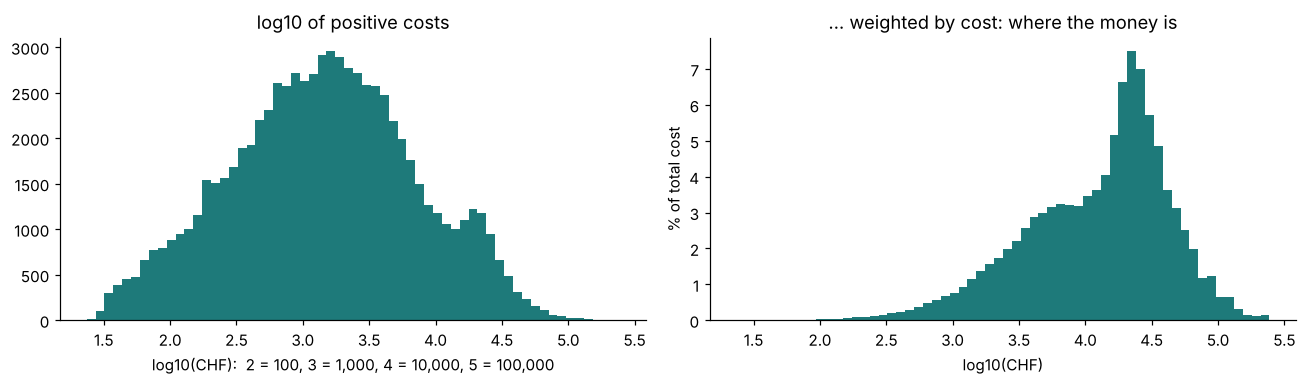

geometric mean of positive costs (what a log-scale model aims at): CHF 1,431 · arithmetic mean: CHF 4,629


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
pos = c[c > 0]
ax[0].hist(np.log10(pos), bins=60, color="#1E7A7A")
ax[0].set(title="log10 of positive costs", xlabel="log10(CHF):  2 = 100, 3 = 1,000, 4 = 10,000, 5 = 100,000")
ax[1].hist(np.log10(pos), bins=60, color="#1E7A7A", weights=pos / pos.sum() * 100)
ax[1].set(title="… weighted by cost: where the money is", xlabel="log10(CHF)", ylabel="% of total cost")
plt.tight_layout(); plt.show()
print(f"geometric mean of positive costs (what a log-scale model aims at): CHF {10**np.log10(pos).mean():,.0f} · arithmetic mean: CHF {pos.mean():,.0f}")

On a base-10 log scale each unit is a factor of ten, so CHF 100, 1,000 and 10,000 are equally spaced. The bell shape becomes visible: most people cost between CHF 300 and CHF 10,000. The right panel weights each person by their cost and shows **where the money is**: about 60% of all francs are spent on person-years above CHF 10,000, which are only about one in ten.

The log scale therefore helps the *eye*. It would be a mistake to let it guide the *model* without thought, for two reasons:

1. **Zeros.** The 9% of people with no cost have no logarithm; any fix such as $\log(1 + y)$ is arbitrary.
2. **The wrong average.** A model trained to predict $\log y$ well predicts the *mean of the logs*, i.e. the **geometric mean**, which lies far below the arithmetic mean (see the printed numbers). A premium must cover the **arithmetic** mean: every franc of the expensive cases has to be paid. Section 5 measures how large this error is.

### 1.3 · Two facts that any model must capture

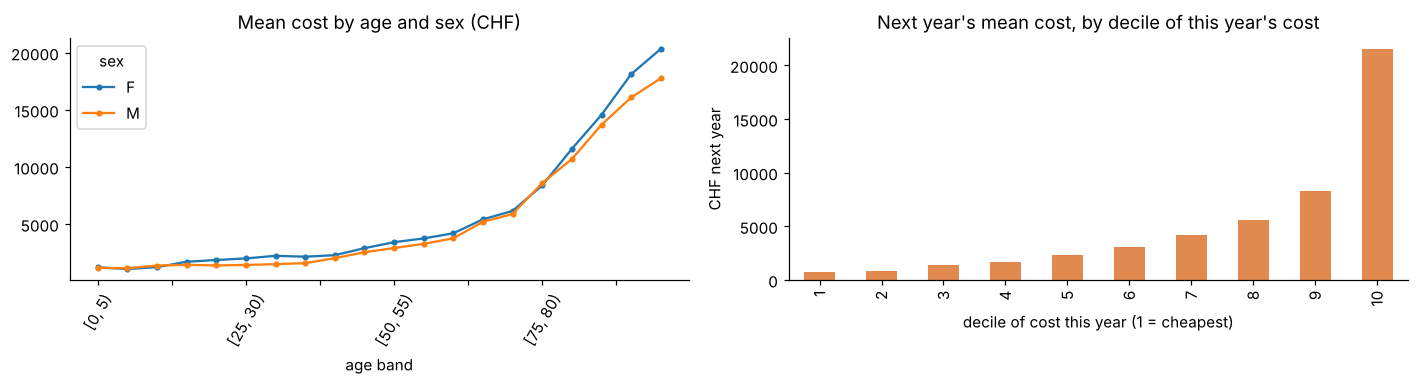

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
by_age = py.groupby([pd.cut(py.age, range(0, 101, 5), right=False), "sex"], observed=True).okp_gross_cost.mean().unstack()
by_age.plot(ax=ax[0], marker="o", ms=3, title="Mean cost by age and sex (CHF)"); ax[0].set_xlabel("age band"); ax[0].tick_params(axis="x", rotation=60)
pair = py.sort_values(["person_id", "year"]).assign(nxt=lambda d: d.groupby("person_id").okp_gross_cost.shift(-1)).dropna()
dec = pd.qcut(pair.okp_gross_cost.rank(method="first"), 10, labels=range(1, 11))
pair.groupby(dec, observed=True).nxt.mean().plot.bar(ax=ax[1], color="#E08A4F", title="Next year's mean cost, by decile of this year's cost")
ax[1].set(xlabel="decile of cost this year (1 = cheapest)", ylabel="CHF next year")
plt.tight_layout(); plt.show()

* **Age:** costs are flat in childhood and rise steeply after 50; an 80-year-old costs about eight times as much as a 30-year-old.
* **Persistence:** people in this year's most expensive decile cost more than twenty times as much next year as people in the cheapest decile. Chronic illness persists, so **last year's cost is the strongest predictor of next year's cost**. Keep this in mind: it will explain the verdict of this notebook.

## 2 · The prediction task

### 2.1 · Rows, features and target
`cu.build_regression_panel()` builds one row per person and year $t$, with features known at the end of year $t$ and the **target = cost in year $t+1$**. An insurer sets next year's price in autumn, so it can use only what it knows then.

| group | features | plain meaning |
|---|---|---|
| who | `age_next`, `sex`, `household_size`, `income_band`, `employment` | demographics |
| where | `canton`, `premium_region`, `municipality_type`, `language` | place of residence |
| contract for $t+1$ | `okp_insurer_next`, `okp_model_next`, `deductible_next`, `accident_cover_next`, `age_class_next` | chosen in November of year $t$, so known in time |
| history | `log_cost_t`, `log_cost_t1`, `log_cost_t2`, `zero_cost_t`, `n_gp_visits`, `n_specialist_visits`, `n_inpatient_stays`, `inpatient_days`, `n_accidents` | last three years of care (−1 = no data that year) |
| health flags | `ra_pharma_cost_group` (takes medication for a chronic illness), `ra_hospital_prev_year_gt3_nights` | derived from claims |
| other cover | `has_amb`, `has_hosp_semi_priv`, `n_vvg_reservations` | supplementary products held |

`exposure_next` is the fraction of year $t+1$ the person was insured (people are born, die or move during a year); we predict the **annualised** cost and weight each row by its exposure.

In [5]:
df = cu.build_regression_panel(py)
CAT, NUM = cu.CAT_REG, cu.NUM_REG
print(f"{len(df):,} rows · {len(CAT)} categorical and {len(NUM)} numeric features")
df[["person_id", "year", "age_next", "deductible_next", "log_cost_t", "log_cost_t1", "cost_next", "exposure_next"]].head()

74,466 rows · 11 categorical and 17 numeric features


,person_id,year,age_next,deductible_next,log_cost_t,log_cost_t1,cost_next,exposure_next
0,1,2014,70,300,6.366,-1.000,405.09,1.0
1,1,2015,71,300,6.007,6.366,1662.19,1.0
2,2,2014,28,2000,7.360,-1.000,93.95,1.0
3,2,2015,29,2000,4.553,7.360,944.23,1.0
4,2,2016,30,1000,6.851,4.553,5558.96,1.0


### 2.2 · Split by time, and remove the cost trend
Pricing always predicts the **future**, so we split by time and never let the model see later years than the ones it predicts:

| set | feature year $t$ | target year $t+1$ | use |
|---|---|---|---|
| train | 2014–2023 | 2015–2024 | fit the models |
| validation | 2024 | 2025 | early stopping, choices |
| test | 2025 | 2026 | final scores, untouched |

Health costs grow every year (prices, new treatments, more care per person). A model trained on 2015–2024 would therefore under-predict 2026. We estimate a log-linear **trend** on the training years only, divide every target by it, model the de-trended cost `y`, and multiply predictions back.

In [6]:
yearly = df[df.year <= 2023].groupby("year").apply(lambda d: d.cost_next.sum() / d.exposure_next.sum())
b, a = np.polyfit(yearly.index.values, np.log(yearly.values), 1)
df["trend"] = np.exp(a + b * df.year.values)          # cost level of target year t+1, indexed by t
df["y"] = df.cost_next / df.exposure_next / df.trend  # de-trended annualised cost (≈ 1 on average)
df["w"] = df.exposure_next
tr, va, te = df[df.year <= 2023], df[df.year == 2024], df[df.year == 2025]
y_te = (te.cost_next / te.exposure_next).values      # observed 2026 cost, CHF per year
print(f"cost trend: {np.expm1(b):+.1%} per year · train {len(tr):,} · validation {len(va):,} · test {len(te):,}")

cost trend: +2.7% per year · train 61,774 · validation 6,322 · test 6,370


## 3 · Which loss? The model must predict the mean

### 3.1 · What we need from a prediction
The premium for a group must equal the group's **average** cost. A model is useful for pricing if its predictions, summed over any group, match the group's actual total. This requirement selects the loss function:

| loss | what the best prediction equals | consequence for pricing |
|---|---|---|
| squared error on CHF | the conditional **mean** | right target, but a single CHF 200,000 case dominates training |
| squared error on log cost | the mean of the logs = **geometric mean** | systematically too low: under-prices every group |
| absolute error (MAE) | the **median** | far too low for skewed costs |
| Poisson or **Tweedie** deviance with log link | the conditional **mean** | right target, and errors scaled to the size of the case |

### 3.2 · Why Tweedie fits annual health costs
Think of a person's yearly cost as a **sum of invoices**: a random number $N$ of invoices (Poisson), each with a random positive amount (Gamma). The total is zero when $N = 0$ and continuous and right-skewed otherwise — exactly the spike plus long tail of Section 1. This compound Poisson–Gamma distribution belongs to the **Tweedie** family (Jørgensen, 1987), whose variance grows with the mean: $\operatorname{Var}(Y) = \phi\,\mu^{p}$ with $1 < p < 2$; we use $p = 1.5$. Because the variance grows with $\mu$, a CHF 10,000 error on a CHF 100,000 patient counts as ordinary noise, while the same error on a healthy 25-year-old counts as a large mistake.

**Which costs are Tweedie by nature, and which are not?**

| quantity | Tweedie? | better choice |
|---|---|---|
| annual cost per insured (many zeros, sum of claims) | ✅ yes | Tweedie, $1<p<2$ |
| number of doctor visits or claims | no (counts) | Poisson, negative binomial |
| amount of one claim, given a claim occurred | no (never zero) | Gamma, log-normal |
| very large losses (top 0.1%) | tail heavier than Tweedie | cap and model separately (Pareto) |
| cost of people with a high deductible who do not submit small bills | zeros for another reason | hurdle or zero-inflated model |
| a yes/no event (hospital stay next year) | no | Bernoulli (cross-entropy) |

### 3.3 · The loss in code
Minimising the Tweedie deviance is equivalent to minimising, with $\eta = \log\mu$ the network output,
$$\ell(y,\eta) = -\frac{y\,e^{(1-p)\eta}}{1-p} + \frac{e^{(2-p)\eta}}{2-p}.$$

### ✏️ Exercise 1 — implement the Tweedie loss
Return the exposure-weighted mean of $\ell$. Work with `eta` (the log prediction): `torch.exp` of a moderate number is safe, `mu ** (1-p)` for a tiny `mu` is not.

In [7]:
# ✅ SOLUTION
def tweedie_loss(y, eta, w, p=1.5):
    loss = -y * torch.exp((1 - p) * eta) / (1 - p) + torch.exp((2 - p) * eta) / (2 - p)
    return (w * loss).sum() / w.sum()

In [8]:
# Test: for a constant true value y = 2, the loss must be smallest at eta = log(2)
yt, wt = torch.full((5,), 2.0), torch.ones(5)
grid = np.log(2) + np.linspace(-.5, .5, 11)
assert int(np.argmin([tweedie_loss(yt, torch.full((5,), float(g)), wt).item() for g in grid])) == 5
print("✓ the Tweedie loss is minimal at the true value")

# The four losses of Section 3.1, each paired with the transformation from network output to prediction
LOSSES = {
    "tweedie":     (tweedie_loss,                                                      np.exp),
    "poisson":     (lambda y, o, w: (w * (torch.exp(o) - y * o)).sum() / w.sum(),         np.exp),
    "mse":         (lambda y, o, w: (w * (y - o) ** 2).sum() / w.sum(),                   lambda o: o),
    "mse_on_log":  (lambda y, o, w: (w * (torch.log1p(y) - o) ** 2).sum() / w.sum(),      np.expm1),
}

✓ the Tweedie loss is minimal at the true value


## 4 · A neural network with embeddings for every categorical variable

### 4.1 · One-hot coding versus embeddings
A categorical variable such as `canton` (26 values) can enter a network in two ways:
* **one-hot:** 26 columns of 0/1; the network learns 26 unrelated numbers per hidden unit;
* **embedding:** a learned table that maps each canton to a short vector, e.g. 6 numbers (Guo & Berkhahn, 2016). Cantons with similar effects end up with similar vectors, so information is shared, and the number of parameters stays small.

There is no reason to embed only high-cardinality variables: we embed **every** categorical feature and let training decide what each vector encodes. A common rule of thumb sets the dimension to about $1.6\,n^{0.56}$ for $n$ levels (used by the fast.ai library), capped here at 8.

In [9]:
codes = {c: {v: i for i, v in enumerate(sorted(df[c].astype(str).unique()))} for c in CAT}
def emb_dim(n): return int(min(8, max(2, round(1.6 * n ** 0.56))))
print(pd.DataFrame({"levels": {c: len(codes[c]) for c in CAT}, "embedding dimension": {c: emb_dim(len(codes[c])) for c in CAT}}).T.to_string())

num_scaler = StandardScaler().fit(tr[NUM])
def tab_inputs(d):
    """numeric block (standardised) and integer codes of the categorical variables"""
    return [torch.tensor(num_scaler.transform(d[NUM]), dtype=torch.float32),
            torch.tensor(np.stack([d[c].astype(str).map(codes[c]).values for c in CAT], 1), dtype=torch.long)]
def target(d): return torch.tensor(d.y.values, dtype=torch.float32), torch.tensor(d.w.values, dtype=torch.float32)
D_tr, D_va, D_te = [(tab_inputs(d), *target(d)) for d in (tr, va, te)]

                     sex  canton  premium_region  municipality_type  language  employment  okp_insurer_next  okp_model_next  deductible_next  accident_cover_next  age_class_next
levels                 2      26               3                  3         3           5                 8               4               11                    2               3
embedding dimension    2       8               3                  3         3           4                 5               3                6                    2               3


### 4.2 · The architecture
$$\mathbf{z} = [\,\mathbf{x}_{\text{num}};\ \mathbf{e}_{\text{sex}};\ \mathbf{e}_{\text{canton}};\ \dots;\ \mathbf{e}_{\text{age class}}\,], \qquad \mathbf{h}_1 = \operatorname{ReLU}(W_1\mathbf{z}+\mathbf{b}_1),\quad \mathbf{h}_2 = \operatorname{ReLU}(W_2\mathbf{h}_1+\mathbf{b}_2),\quad o = \mathbf{w}^\top\mathbf{h}_2 + b .$$
The output $o$ becomes a prediction through the transformation that belongs to the loss (exp for Tweedie and Poisson). A GLM is this network without hidden layers; the hidden layers let it learn interactions such as "history matters more for older people".

In [10]:
class TabularNet(nn.Module):
    def __init__(self, hidden=(64, 32), dropout=0.1):
        super().__init__()
        self.emb = nn.ModuleList([nn.Embedding(len(codes[c]), emb_dim(len(codes[c]))) for c in CAT])
        d = len(NUM) + sum(emb_dim(len(codes[c])) for c in CAT); layers = []
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]; d = h
        self.body, self.head = nn.Sequential(*layers), nn.Linear(d, 1)
    def forward(self, x_num, x_cat):
        z = torch.cat([x_num] + [m(x_cat[:, i]) for i, m in enumerate(self.emb)], dim=1)
        return self.head(self.body(z)).squeeze(1)

def start_value(loss):
    """initial output bias: the network starts by predicting the average, in the scale of its loss"""
    return {"tweedie": np.log(tr.y.mean()), "poisson": np.log(tr.y.mean()), "mse": tr.y.mean(), "mse_on_log": np.log1p(tr.y).mean()}[loss]

def train(model, D_train, D_val, loss="tweedie", epochs=25, lr=2e-3, batch=512, verbose=False):
    """mini-batch AdamW with early stopping on the validation loss"""
    torch.manual_seed(SEED); loss_fn = LOSSES[loss][0]
    with torch.no_grad(): model.head.bias.fill_(float(start_value(loss)))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    X, y, w = D_train; n = len(y); best = (np.inf, None, -1)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, batch):
            j = perm[i:i + batch]; opt.zero_grad()
            loss_fn(y[j], model(*[x[j] for x in X]), w[j]).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        model.eval()
        with torch.no_grad(): lv = loss_fn(D_val[1], model(*D_val[0]), D_val[2]).item()
        if lv < best[0]: best = (lv, {k: v.clone() for k, v in model.state_dict().items()}, ep)
    model.load_state_dict(best[1])
    if verbose: print(f"best epoch {best[2] + 1}/{epochs}")
    return model

def predict(model, D, loss="tweedie"):
    model.eval()
    with torch.no_grad(): return np.clip(LOSSES[loss][1](model(*D[0]).numpy()), 1e-6, None)

## 5 · Experiment: the same network, four losses
We train the identical architecture four times, changing only the loss. Every model is scored on the 2026 test year with four numbers:
* **total ratio** = predicted total / actual total: the pricing requirement; 1.00 is perfect;
* **Tweedie deviance** (lower is better): fit of the whole distribution;
* **Gini** (higher is better): how well the model ranks people from cheap to expensive;
* **MAE**: mean absolute error in CHF per person.

In [11]:
def scores(name, pred_detrended, d=te):
    """score a de-trended prediction on the observed annualised cost of year t+1"""
    y_obs, mu = (d.cost_next / d.exposure_next).values, pred_detrended * d.trend.values
    null = np.full_like(y_obs, np.average(tr.y, weights=tr.w)) * d.trend.values      # everybody gets the average
    dev, dev0 = cu.tweedie_deviance(y_obs, mu, w=d.w), cu.tweedie_deviance(y_obs, null, w=d.w)
    return dict(model=name, total_ratio=np.average(mu, weights=d.w) / np.average(y_obs, weights=d.w), deviance=dev,
                D2=1 - dev / dev0, gini=cu.gini(y_obs, mu), MAE_CHF=np.average(np.abs(y_obs - mu), weights=d.w))

loss_runs, mlp_models = [], {}
t0 = time.time()
for loss in LOSSES:
    m = train(TabularNet(), D_tr, D_va, loss=loss)
    mlp_models[loss] = m
    loss_runs.append(scores(f"MLP · {loss}", predict(m, D_te, loss)))
print(f"4 networks trained in {time.time() - t0:.0f} s")
pd.DataFrame(loss_runs).set_index("model").style.format({"total_ratio": "{:.3f}", "deviance": "{:.2f}", "D2": "{:.3f}", "gini": "{:.3f}", "MAE_CHF": "{:,.0f}"})

4 networks trained in 47 s


,total_ratio,deviance,D2,gini,MAE_CHF
model,,,,,
MLP · tweedie,0.982,65.58,0.580,0.832,"3,284"
MLP · poisson,0.987,65.88,0.578,0.830,"3,339"
MLP · mse,0.962,66.24,0.576,0.831,"3,252"
MLP · mse_on_log,0.819,69.68,0.554,0.833,"3,034"


**Reading the table.**
* **Squared error on log cost predicts far too little in total** — roughly a fifth too little. A premium built on it would lose about one franc in five. Section 1.2 explains why: it targets the geometric mean.
* At the same time it has the **lowest MAE**. MAE rewards predicting the typical (median-like) person and punishes the costly tail less. This is a warning about metrics: the metric that looks best can be the one that bankrupts the insurer.
* Tweedie, Poisson and plain squared error all target the mean and get the total right within a few percent. With 60,000 training rows they rank people almost equally well. Squared error works here because the data set is large; on smaller portfolios a few extreme cases make it unstable, which is why actuaries prefer the Tweedie or Poisson deviance (Wüthrich & Merz, 2023).

From now on every network uses the **Tweedie** loss.

## 6 · The full line-up: from the law's tariff cell to recurrent networks

### 6.1 · Classical models
* **Average for everybody** — the "null" model, used for $D^2$ below.
* **Tariff cell** — the average of canton × age class: the structure the law allows for basic premiums.
* **GLM** (Tweedie, log link) with demographics only, then with all features; age enters as a spline.
* **Gradient boosting** — many small trees fitted in sequence, the usual winner on tables (Grinsztajn et al., 2022).

In [12]:
results = [scores("average for everybody", np.full(len(te), np.average(tr.y, weights=tr.w)))]
cell = tr.groupby(["canton", "age_class_next"]).apply(lambda d: np.average(d.y, weights=d.w)).rename("cell")
results.append(scores("tariff cell (canton × age class)", te.join(cell, on=["canton", "age_class_next"])["cell"].values))

def glm_fit(cats, nums):
    steps = [("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cats), ("age", SplineTransformer(n_knots=6), ["age_next"])]
    if nums: steps.append(("num", StandardScaler(), nums))
    pre = ColumnTransformer(steps)
    m = TweedieRegressor(power=1.5, link="log", alpha=1e-4, max_iter=3000).fit(pre.fit_transform(tr), tr.y, sample_weight=tr.w)
    return lambda d: m.predict(pre.transform(d))
glm_demo = glm_fit(["sex", "canton", "premium_region"], [])
glm_full = glm_fit(CAT, [c for c in NUM if c != "age_next"])
results += [scores("GLM · demographics", glm_demo(te)), scores("GLM · all features", glm_full(te))]

def tree_frame(d, extra=None):
    X = d[CAT + NUM].copy()
    for c in CAT: X[c] = pd.Categorical(X[c].astype(str), categories=sorted(codes[c]))
    return X if extra is None else pd.concat([X.reset_index(drop=True), extra.reset_index(drop=True)], axis=1)
def gbm_fit(Xtr):
    return HistGradientBoostingRegressor(loss="poisson", learning_rate=0.05, max_iter=600, min_samples_leaf=100, l2_regularization=1.0,
                                         categorical_features="from_dtype", early_stopping=True, validation_fraction=0.15,
                                         random_state=SEED).fit(Xtr, tr.y, sample_weight=tr.w)
gbm = gbm_fit(tree_frame(tr))
results.append(scores("gradient boosting", gbm.predict(tree_frame(te))))
results.append([r for r in loss_runs if r["model"] == "MLP · tweedie"][0] | {"model": "MLP + embeddings"})
pd.DataFrame(results).set_index("model").style.format({"total_ratio": "{:.3f}", "deviance": "{:.2f}", "D2": "{:.3f}", "gini": "{:.3f}", "MAE_CHF": "{:,.0f}"})

,total_ratio,deviance,D2,gini,MAE_CHF
model,,,,,
average for everybody,0.951,156.19,0.000,0.216,"5,825"
tariff cell (canton × age class),0.961,142.37,0.088,0.247,"5,654"
GLM · demographics,0.934,106.90,0.316,0.649,"4,649"
GLM · all features,0.997,68.48,0.562,0.823,"3,518"
gradient boosting,1.005,64.34,0.588,0.836,"3,226"
MLP + embeddings,0.982,65.58,0.580,0.832,"3,284"


$D^2 = 1 - \text{deviance}/\text{deviance of "average for everybody"}$ is the **share of the deviance the model explains**, the analogue of $R^2$ for Tweedie models: 0 means "no better than the average", 1 means perfect.

### ✏️ Exercise 2 — what did the embeddings learn?
The deductible is a number (CHF 0–2,500) but we fed it as a *category*: the network was never told that 2,500 > 300. Project the learned `deductible_next` embedding vectors of `mlp_models["tweedie"]` on their first principal component and plot the component against the deductible amount. Did the network discover the order? Repeat for `okp_model_next` (standard, family doctor, HMO, telmed).

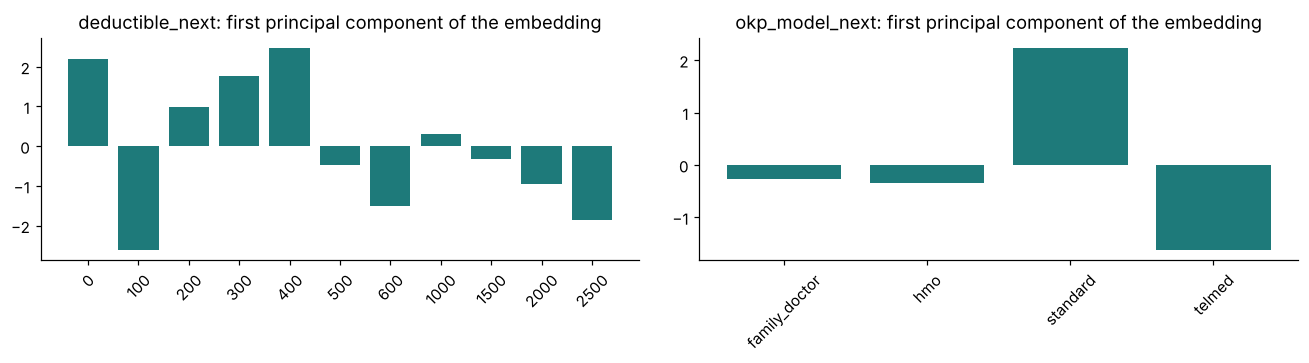

In [13]:
# ✅ SOLUTION
mlp = mlp_models["tweedie"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for a_, var in zip(ax, ["deductible_next", "okp_model_next"]):
    E = mlp.emb[CAT.index(var)].weight.detach().numpy()
    pc1 = (E - E.mean(0)) @ np.linalg.svd(E - E.mean(0), full_matrices=False)[2][0]
    labels = list(codes[var])
    order = np.argsort([int(l) for l in labels]) if var == "deductible_next" else np.arange(len(labels))
    a_.bar([labels[i] for i in order], pc1[order], color="#1E7A7A"); a_.set(title=f"{var}: first principal component of the embedding")
    a_.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**What to look for.** For adults (CHF 300–2,500), the component falls broadly from high at CHF 300 to low at CHF 2,500, with some noise in between: the network recovered most of the order from the data alone, because people with high deductibles cost less (Lecture 3 shows how much of that is *selection* of healthy people). Rare deductibles (100, 200, 400, 600 — children with few observations) sit anywhere: an embedding is only as good as the data behind each level. For the care model, the alternative models (family doctor, HMO, telmed) should lie apart from `standard`.

### 6.2 · Recurrent networks over monthly histories
The annual features summarise a year by totals. A **recurrent neural network** reads the history month by month. For each row we build a matrix of **36 months × 5 channels**: log cost, log number of doctor visits, hospital admissions, log medication cost, and the share of the month the person was insured.

A recurrent network keeps a hidden state $\mathbf{h}_t$ and updates it month by month:
* **vanilla RNN:** $\mathbf{h}_t = \tanh(W\mathbf{x}_t + U\mathbf{h}_{t-1} + \mathbf{b})$. Gradients pass through the same matrix $U$ at every step, so over long sequences they shrink or explode (Bengio et al., 1994);
* **LSTM** (Hochreiter & Schmidhuber, 1997): a separate **cell state** $\mathbf{c}_t$ is updated additively, $\mathbf{c}_t = \mathbf{f}_t\odot\mathbf{c}_{t-1} + \mathbf{i}_t\odot\tilde{\mathbf{c}}_t$, with a *forget* gate $\mathbf{f}_t$, an *input* gate $\mathbf{i}_t$ and an *output* gate, each a sigmoid of $\mathbf{x}_t$ and $\mathbf{h}_{t-1}$. The additive path lets information and gradients survive many steps;
* **GRU** (Cho et al., 2014): a lighter variant with two gates.

The final hidden state summarises the 36 months; we concatenate it with the non-history features and embeddings and predict with the Tweedie loss.

In [14]:
ev = cu.load("events")[["person_id", "date", "year", "care_type", "okp_gross"]]
ev["month"] = (ev.year - 2014) * 12 + pd.to_datetime(ev.date).dt.month - 1
pids = np.sort(df.person_id.unique()); pix = {p: i for i, p in enumerate(pids)}
M = np.zeros((len(pids), 13 * 12, 5), np.float32)                       # person × month (2014-01 … 2026-12) × channel
e = ev[ev.person_id.isin(pix)]; ii, mm = e.person_id.map(pix).values, e.month.values
np.add.at(M[:, :, 0], (ii, mm), e.okp_gross.values)
np.add.at(M[:, :, 1], (ii, mm), e.care_type.isin(["gp_visit", "specialist_visit"]).values.astype(np.float32))
np.add.at(M[:, :, 2], (ii, mm), (e.care_type == "inpatient_stay").values.astype(np.float32))
np.add.at(M[:, :, 3], (ii, mm), np.where(e.care_type == "medication", e.okp_gross.values, 0))
M[:, :, [0, 1, 3]] = np.log1p(M[:, :, [0, 1, 3]])
ins = np.zeros((len(pids), 13), np.float32); pp = py[py.person_id.isin(pix)]
ins[pp.person_id.map(pix).values, pp.year.values - 2014] = pp.insured_days.values / 365
M[:, :, 4] = np.repeat(ins, 12, axis=1)

def monthly(d):
    """the 36 months of years t-2, t-1, t for every row (zeros before 2014)"""
    r, end = d.person_id.map(pix).values, (d.year.values - 2014 + 1) * 12
    idx = end[:, None] - 36 + np.arange(36)[None, :]
    return torch.tensor(M[r[:, None], np.clip(idx, 0, None)] * (idx >= 0)[..., None])

STATIC = ["age_next", "household_size", "income_band", "has_amb", "has_hosp_semi_priv", "n_vvg_reservations"]
st_scaler = StandardScaler().fit(tr[STATIC])
def seq_inputs(d):
    return [monthly(d), torch.tensor(st_scaler.transform(d[STATIC]), dtype=torch.float32), tab_inputs(d)[1]]
S_tr, S_va, S_te = [(seq_inputs(d), *target(d)) for d in (tr, va, te)]
print("monthly history tensor (rows, months, channels):", tuple(S_tr[0][0].shape))

monthly history tensor (rows, months, channels): (61774, 36, 5)


In [15]:
class SequenceNet(nn.Module):
    def __init__(self, cell="lstm", hidden=32):
        super().__init__()
        self.rnn = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell](5, hidden, batch_first=True)
        self.emb = nn.ModuleList([nn.Embedding(len(codes[c]), emb_dim(len(codes[c]))) for c in CAT])
        d = hidden + len(STATIC) + sum(emb_dim(len(codes[c])) for c in CAT)
        self.body, self.head = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(0.1)), nn.Linear(64, 1)
    def forward(self, months, x_static, x_cat):
        out, _ = self.rnn(months)                      # out: hidden state after every month
        z = torch.cat([out[:, -1], x_static] + [m(x_cat[:, i]) for i, m in enumerate(self.emb)], dim=1)
        return self.head(self.body(z)).squeeze(1)

seq_models = {}
for cell in ["rnn", "lstm"]:
    t0 = time.time()
    seq_models[cell] = train(SequenceNet(cell), S_tr, S_va, epochs=15)
    results.append(scores(f"{cell.upper()} over 36 months", predict(seq_models[cell], S_te)))
    print(f"{cell.upper()} trained in {time.time() - t0:.0f} s")
board = pd.DataFrame(results).set_index("model")
board.style.format({"total_ratio": "{:.3f}", "deviance": "{:.2f}", "D2": "{:.3f}", "gini": "{:.3f}", "MAE_CHF": "{:,.0f}"})

RNN trained in 20 s


LSTM trained in 44 s


,total_ratio,deviance,D2,gini,MAE_CHF
model,,,,,
average for everybody,0.951,156.19,0.000,0.216,"5,825"
tariff cell (canton × age class),0.961,142.37,0.088,0.247,"5,654"
GLM · demographics,0.934,106.90,0.316,0.649,"4,649"
GLM · all features,0.997,68.48,0.562,0.823,"3,518"
gradient boosting,1.005,64.34,0.588,0.836,"3,226"
MLP + embeddings,0.982,65.58,0.580,0.832,"3,284"
RNN over 36 months,0.931,63.26,0.595,0.840,"3,052"
LSTM over 36 months,1.001,62.14,0.602,0.843,"3,094"


## 7 · How good is "good"? A ceiling, and the verdict on neural networks

### 7.1 · Two yardsticks only synthetic data can offer
A deviance of 62 or a Gini of 0.84 says little on its own. Our data were generated from a known process with hidden variables (`data/ground_truth`): each person's latent **frailty**, smoking, body-mass index and the true start year of each chronic illness. We use them — never available to a real insurer — to build two reference models:

* **Knowable ceiling:** gradient boosting with all features **plus** the hidden state at the end of year $t$ (frailty, smoking, BMI, which chronic illnesses have started and since when). This is roughly the best any insurer could do with perfect knowledge of its customers today.
* **Clairvoyant model:** the same, plus which illnesses will **start next year**. It cheats, because nobody knows that in advance; the gap between the two measures how much of next year's cost is pure chance.

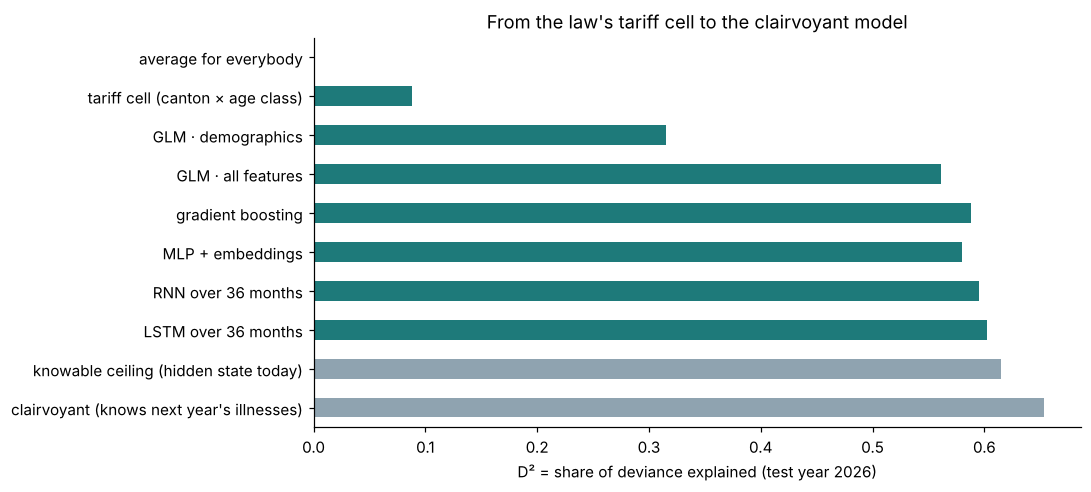

best real model D² = 0.602 · knowable ceiling D² = 0.615 → the best model reaches 98% of what is knowable today


In [16]:
truth = pd.read_csv(cu.DATA / "ground_truth" / "person_latent_truth.csv").set_index("person_id")
CONDS = ["cardiovascular", "diabetes", "respiratory", "mental", "musculoskeletal", "cancer", "dementia"]
def hidden_state(d, future=False):
    X = pd.DataFrame({"frailty": d.person_id.map(truth.frailty).values, "smoker": d.person_id.map(truth.smoker).astype(float).values,
                      "bmi": d.person_id.map(truth.bmi).values})
    for c_ in CONDS:
        onset = d.person_id.map(truth["onset_" + c_]).values
        X["has_" + c_] = (onset <= d.year.values).astype(float)
        X["years_with_" + c_] = np.where(onset <= d.year.values, d.year.values - onset, -1)
        if future: X["starts_next_year_" + c_] = (onset == d.year.values + 1).astype(float)
    return X
for name, fut in (("knowable ceiling (hidden state today)", False), ("clairvoyant (knows next year's illnesses)", True)):
    m = gbm_fit(tree_frame(tr, hidden_state(tr, fut)))
    results.append(scores(name, m.predict(tree_frame(te, hidden_state(te, fut)))))
board = pd.DataFrame(results).set_index("model")
fig, ax = plt.subplots(figsize=(9, 4.6))
board.D2.iloc[::-1].plot.barh(ax=ax, color=["#8FA3B0" if "ceiling" in i or "clairvoyant" in i else "#1E7A7A" for i in board.index[::-1]])
ax.set(xlabel="D² = share of deviance explained (test year 2026)", ylabel="", title="From the law's tariff cell to the clairvoyant model"); plt.show()
best = board.drop(["knowable ceiling (hidden state today)", "clairvoyant (knows next year's illnesses)"]).D2.max()
print(f"best real model D² = {best:.3f} · knowable ceiling D² = {board.loc['knowable ceiling (hidden state today)', 'D2']:.3f} "
      f"→ the best model reaches {best / board.loc['knowable ceiling (hidden state today)', 'D2']:.0%} of what is knowable today")

**Reading the ladder.**
* The tariff cell explains little; a smooth age curve explains much more; claims history adds the largest step.
* All models with history — GLM, gradient boosting, MLP, RNN, LSTM — sit close together, and the best of them reaches the vast majority of the **knowable ceiling**. Even perfect knowledge of every customer's hidden health today would improve the prediction only modestly.
* The **clairvoyant** model is clearly better: much of what remains unexplained is **chance** — who will develop cancer, have an accident or die next year. No model can learn that from today's data, and that is precisely why insurance exists: it pools risks that nobody can predict.

### 7.2 · Why do neural networks not help here?
Two observations explain it.

1. **The signal is simple and strong.** Next year's cost depends mostly on last year's cost, age and chronic medication, roughly multiplicatively. A GLM with a log link already represents this structure; trees and networks add a few interactions.
2. **The RNN/LSTM gain comes from information, not from the architecture.** The recurrent networks see *monthly* data, which split cost into medication and hospital care and show *when* in the year costs occurred. If we hand gradient boosting the same information as a few summary columns, it should catch up. The next cell tests this.

In [17]:
def monthly_summaries(d):
    S = monthly(d).numpy(); cost, med = np.expm1(S[:, :, 0]), np.expm1(S[:, :, 3])
    return pd.DataFrame({"cost_last_quarter": np.log1p(cost[:, -3:].sum(1)), "cost_last_half_year": np.log1p(cost[:, -6:].sum(1)),
                         "medication_t": np.log1p(med[:, -12:].sum(1)), "medication_t1": np.log1p(med[:, -24:-12].sum(1)),
                         "admissions_last_quarter": S[:, -3:, 2].sum(1), "months_with_cost_t": (cost[:, -12:] > 0).sum(1)})
m = gbm_fit(tree_frame(tr, monthly_summaries(tr)))
results.insert(len(results) - 2, scores("gradient boosting + 6 monthly summaries", m.predict(tree_frame(te, monthly_summaries(te)))))
board = pd.DataFrame(results).set_index("model")
board.style.format({"total_ratio": "{:.3f}", "deviance": "{:.2f}", "D2": "{:.3f}", "gini": "{:.3f}", "MAE_CHF": "{:,.0f}"})

,total_ratio,deviance,D2,gini,MAE_CHF
model,,,,,
average for everybody,0.951,156.19,0.000,0.216,"5,825"
tariff cell (canton × age class),0.961,142.37,0.088,0.247,"5,654"
GLM · demographics,0.934,106.90,0.316,0.649,"4,649"
GLM · all features,0.997,68.48,0.562,0.823,"3,518"
gradient boosting,1.005,64.34,0.588,0.836,"3,226"
MLP + embeddings,0.982,65.58,0.580,0.832,"3,284"
RNN over 36 months,0.931,63.26,0.595,0.840,"3,052"
LSTM over 36 months,1.001,62.14,0.602,0.843,"3,094"
gradient boosting + 6 monthly summaries,0.999,62.40,0.601,0.842,"3,113"


With six summary columns of the same monthly information, gradient boosting lands next to the recurrent networks. (Note also the vanilla RNN: it ranks people well but its total is several percent too low. Early stopping on the validation loss does not guarantee a correct total; pricing teams therefore re-balance a network's predictions on recent data before use — Lecture 3.)

 **Information beats architecture**: when the relevant structure can be summarised by a few numbers an analyst can think of, any flexible model will do. Neural networks earn their place when the signal hides in raw, high-dimensional inputs that resist summarising — Practical 3 shows such a case.

*Is the remaining difference of a few deviance points between the best models real?* Lecture 3 answers with a bootstrap; for now, treat differences below about one point as noise.

## 8 · Who is mispredicted, in which direction — and does it matter?

### 8.1 · Groups the insurer can see
We take the LSTM's 2026 predictions (any of the top models gives the same picture) and compare, for each group, the **mean predicted** with the **mean observed** cost. A ratio below 1 means the group is **under-predicted** (it costs more than expected), above 1 **over-predicted**. We compare francs: the predicted annual cost times the time each person was insured, against the francs actually spent.

In [18]:
pred_best = predict(seq_models["lstm"], S_te) * te.trend.values      # the LSTM, one of the best models
# compare money: predicted annual rate × years insured  versus  the francs actually spent
E = te.assign(pred=pred_best * te.w.values, obs=te.cost_next.values)
E["age_band"] = pd.cut(E.age_next, [-1, 18, 30, 45, 60, 75, 120], labels=["0-18", "19-30", "31-45", "46-60", "61-75", "76+"])
E["chronic_medication"] = np.where(E.ra_pharma_cost_group > 0, "yes", "no")
def by(col):
    g = E.groupby(col, observed=True).agg(people=("obs", "size"), observed=("obs", "mean"), predicted=("pred", "mean"))
    g["ratio"] = g.predicted / g.observed; g["gap_CHF"] = g.predicted - g.observed
    return g
pd.concat({c_: by(c_) for c_ in ["age_band", "sex", "chronic_medication"]}).style.format({"observed": "{:,.0f}", "predicted": "{:,.0f}", "ratio": "{:.2f}", "gap_CHF": "{:+,.0f}"})

Across most groups the insurer can observe, the model is right on average (ratios close to 1). The clearest exception is **children**, who cost about 6% more than predicted (young adults about 4%). With roughly 1,100 children, random error alone would typically be 2–3% (Section 8.3 shows how to judge this), so the gap is probably systematic: children's costs come from infections and accidents that the history captures poorly. For an insurer with many families, this is a real under-pricing risk.

### 8.2 · What happened to the people the model got wrong?
The big individual errors come from **events** — some in the past, some in the future. We flag them from the claims and the hidden truth.

In [19]:
evd = cu.load("events")[["person_id", "year", "care_type", "diagnosis_group"]]
flag = evd.assign(childbirth=evd.diagnosis_group.eq("childbirth"),
                  accident=evd.care_type.str.startswith("accident") | evd.diagnosis_group.eq("severe_injury"),
                  end_of_life=evd.diagnosis_group.eq("end_of_life")).groupby(["person_id", "year"])[["childbirth", "accident", "end_of_life"]].any()
E = E.join(flag.add_suffix("_last_year"), on=["person_id", "year"])
nxt = flag.add_suffix("_next_year").reset_index(); nxt["year"] -= 1
E = E.merge(nxt, on=["person_id", "year"], how="left")
E["new_chronic_illness_next_year"] = False
for c_ in CONDS:
    E["new_chronic_illness_next_year"] |= (E.person_id.map(truth["onset_" + c_]) == E.year + 1).values
E = E.fillna(False)
rows = []
for col in ["childbirth_last_year", "accident_last_year", "childbirth_next_year", "accident_next_year", "new_chronic_illness_next_year", "end_of_life_next_year"]:
    g = E[E[col].astype(bool)]
    rows.append(dict(event=col, people=len(g), observed=g.obs.mean(), predicted=g.pred.mean(), ratio=g.pred.mean() / g.obs.mean()))
pd.DataFrame(rows).set_index("event").style.format({"observed": "{:,.0f}", "predicted": "{:,.0f}", "ratio": "{:.2f}"})

,people,observed,predicted,ratio
event,,,,
childbirth_last_year,35,"3,119","3,513",1.13
accident_last_year,594,"6,884","6,201",0.90
childbirth_next_year,27,"8,289","2,808",0.34
accident_next_year,586,"7,648","6,265",0.82
new_chronic_illness_next_year,239,"17,019","8,700",0.51
end_of_life_next_year,25,"31,462","9,966",0.32


**Two kinds of error, two directions.**
* **Over-prediction after one-off events.** A woman who gave birth last year had a high cost, and the model, which does not know *why* the cost was high, expects much of it to recur. The claims say "childbirth", but our features only say "high cost". Event-level information is exactly what the transformer of Lecture 2 reads.
* **Under-prediction of next year's surprises.** People who develop a chronic illness, have an accident, give birth or die next year cost several times what the model predicts. These events are unknowable at pricing time; the gap to the clairvoyant model in Section 7 is made of them.

### 8.3 · Does it matter for Arvena? Pooling
Individual errors are huge: the MAE is of the order of half the average cost. Yet the premium is not set for individuals but for **groups**, and in a group the over- and under-predictions largely cancel. The next cell draws random groups of increasing size from the test year and measures the error of the **group total**.

In [20]:
rng = np.random.default_rng(SEED); rows = []
for n in [10, 50, 200, 1000, 5000]:
    errs = []
    for _ in range(400):
        i = rng.choice(len(E), n, replace=False)
        errs.append(E.pred.values[i].sum() / E.obs.values[i].sum() - 1)
    rows.append(dict(group_size=n, median_abs_error=np.median(np.abs(errs)), p90_abs_error=np.percentile(np.abs(errs), 90)))
pool = pd.DataFrame(rows).set_index("group_size")
pool.style.format("{:.1%}")

,median_abs_error,p90_abs_error
group_size,,
10,24.1%,74.2%
50,11.9%,29.2%
200,6.4%,15.3%
1000,2.4%,6.2%
5000,0.6%,1.3%


For ten people the total can be off by a third or more; for a few thousand people the error shrinks to a few percent — the **law of large numbers**, the mathematical basis of insurance. Two consequences follow for Arvena:
1. **Small groups are volatile.** A canton where Arvena has 50 customers will show large random gains or losses from year to year; insurers hold reserves for this.
2. **Systematic errors do not cancel.** The under-prediction of children (Section 8.1) persists however large the group, and a portfolio rich in families would be under-priced. Pricing teams therefore check calibration by group, not only overall (Lecture 3).

### ✏️ Exercise 3 — your own mispricing check
Choose one variable not used above (for example `deductible_next`, `language`, `okp_model_next` or `household_size`), compute the predicted/observed ratio by level with `by(...)`, and write two sentences: which level is under-priced, and could it be noise given the number of people?

In [21]:
# ✅ SOLUTION
by("deductible_next").sort_values("people", ascending=False).style.format({"observed": "{:,.0f}", "predicted": "{:,.0f}", "ratio": "{:.2f}", "gap_CHF": "{:+,.0f}"})

,people,observed,predicted,ratio,gap_CHF
deductible_next,,,,,
300,1864,"9,527","9,439",0.99,-88
2500,1498,"1,634","1,576",0.96,-58
0,1086,"1,590","1,516",0.95,-74
500,885,"8,618","8,856",1.03,+238
2000,424,"2,384","2,395",1.00,+11
1000,301,"6,696","6,565",0.98,-131
1500,273,"3,389","4,075",1.20,+686
600,13,"1,662",982,0.59,-681
400,11,"1,379","1,366",0.99,-13


## 9 · Deliverable: how much money will Arvena need in 2027?

### 9.1 · Predict 2027 for every current customer
We refit gradient boosting on **all** years (targets up to 2026), re-estimate the trend, and predict 2027 for everyone who renews into 2027, using their 2026 features. We use gradient boosting for the deliverable because it was as accurate as the networks and is quick to refit; any of the top models would do.

### 9.2 · From the cost of care to what Arvena pays
Arvena does not pay the whole bill. The patient pays the **deductible** and 10% of the rest (up to CHF 700 a year), and the canton pays 55% of hospital stays. We convert predicted gross cost into Arvena's payment with the share each deductible level paid in 2026 — an approximation that is exact on average per deductible group.

In [22]:
yearly_all = df.groupby("year").apply(lambda d: d.cost_next.sum() / d.exposure_next.sum())
b_all, a_all = np.polyfit(yearly_all.index.values, np.log(yearly_all.values), 1)
df["y_all"] = df.cost_next / df.exposure_next / np.exp(a_all + b_all * df.year.values)
final = HistGradientBoostingRegressor(loss="poisson", learning_rate=0.05, max_iter=600, min_samples_leaf=100, l2_regularization=1.0,
                                      categorical_features="from_dtype", early_stopping=True, validation_fraction=0.15,
                                      random_state=SEED).fit(tree_frame(df), df.y_all, sample_weight=df.w)
fc = cu.build_forecast_rows(2026)
fc["pred_gross_2027"] = final.predict(tree_frame(fc)) * np.exp(a_all + b_all * 2026)
p26 = py[py.year == 2026]
share_paid = p26.groupby("deductible").okp_benefits_paid.sum() / p26.groupby("deductible").okp_gross_cost.sum()
fc["share_paid"] = fc.deductible.map(share_paid)
fc["pred_paid_2027"] = fc.pred_gross_2027 * fc.share_paid
print("share of the gross cost the insurer pays, by deductible:", share_paid.round(2).to_dict())
out = fc[["person_id", "household_id", "okp_insurer", "canton", "age_next", "deductible", "okp_gross_cost", "pred_gross_2027", "share_paid", "pred_paid_2027"]]
out.to_parquet("outputs/cost_forecast_2027.parquet", index=False)
arv = out[out.okp_insurer == "ARV"]
print(f"\nArvena customers renewing into 2027: {len(arv):,}")
print(f"expected cost of care 2027:  CHF {arv.pred_gross_2027.sum() / 1e6:.2f} million (2026 actual for the same people: CHF {arv.okp_gross_cost.sum() / 1e6:.2f} million)")
print(f"expected claims Arvena pays: CHF {arv.pred_paid_2027.sum() / 1e6:.2f} million")
arv.groupby("canton").agg(customers=("person_id", "size"), expected_paid_CHF=("pred_paid_2027", "sum")).sort_values("customers", ascending=False).head(8).style.format({"expected_paid_CHF": "{:,.0f}"})

share of the gross cost the insurer pays, by deductible: {0: 0.93, 100: 0.91, 200: 0.77, 300: 0.92, 400: 0.76, 500: 0.9, 600: 0.69, 1000: 0.84, 1500: 0.66, 2000: 0.58, 2500: 0.43}

Arvena customers renewing into 2027: 1,194
expected cost of care 2027:  CHF 5.61 million (2026 actual for the same people: CHF 4.92 million)
expected claims Arvena pays: CHF 4.80 million


,customers,expected_paid_CHF
canton,,
ZH,245,"967,257"
VD,236,"935,386"
GE,105,"385,729"
BE,91,"285,741"
NE,60,"243,209"
SG,56,"206,131"
AG,47,"124,022"
LU,45,"208,500"


**Why is 2027 so much higher than 2026 for the same people?** Three effects add up: every customer is one year older; the cost trend continues; and among people alive at the end of 2026, some will fall seriously ill or die in 2027, while the 2026 figure excludes everybody who already died in 2026. In our data, the next-year cost of survivors has exceeded their current-year cost by about 9–12% in every year.

The file `outputs/cost_forecast_2027.parquet` is the input of **Practical 2**, where Arvena chooses its premium.

## 10 · Summary
| question | answer from this notebook |
|---|---|
| Which loss for costs? | one that targets the **mean** (Tweedie, Poisson); squared error on logs under-prices by about a fifth |
| Do networks beat GLM and boosting here? | **no** — all models with history are close, and close to the knowable ceiling |
| Why not? | the signal (history, age, chronic illness) is simple and strong; monthly detail helps any model that receives it |
| Where is the remaining error? | in events nobody can foresee (new illness, accident, death); it is chance, which insurance pools |
| Does it matter? | individual errors cancel in large groups; systematic group errors (here: children) do not |

## 11 · Reflection questions
1. Squared error on log cost had the best MAE but the worst total. Write a one-paragraph memo to a manager who proposes "the model with the lowest average error".
2. The knowable ceiling uses variables no insurer observes. Which observable proxies come closest to frailty, and which of them would be lawful to use in a basic-insurance premium? (Hint: none of the individual ones.)
3. The model over-predicts after childbirth. Propose one feature that would fix this, and explain why it is a cheap version of what a sequence model learns.
4. Pooling makes individual errors harmless for large groups. Why does this argument fail for a new supplementary product with 200 customers?

## References
* Bengio, Y., Simard, P., & Frasconi, P. (1994). Learning long-term dependencies with gradient descent is difficult. *IEEE Transactions on Neural Networks*, 5(2), 157–166.
* Cho, K., van Merriënboer, B., Gulcehre, C., et al. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. *EMNLP*.
* Frees, E. W., Meyers, G., & Cummings, A. D. (2011). Summarizing insurance scores using a Gini index. *JASA*, 106, 1085–1098.
* Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS*.
* Guo, C., & Berkhahn, F. (2016). Entity embeddings of categorical variables. arXiv:1604.06737.
* Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735–1780.
* Jørgensen, B. (1987). Exponential dispersion models. *JRSS B*, 49(2), 127–162.
* Wüthrich, M. V., & Merz, M. (2023). *Statistical Foundations of Actuarial Learning and its Applications*. Springer.